# CCS discovery with successor features on Office: standard SFOLS vs. Certify-or-Grow

The Office counterpart of `SFOLS/13_ccs_speedup_dst.ipynb`: build a CCS whose every policy
carries its successor features, with standard SFOLS and with Certify-or-Grow, first exactly and
then with **learned** SFs (tabular SF Q-learning), and compare the sample cost.

**What is different from DST.**
- *Domain:* `Office` from `RM/sf-fsa-vi/envs/grid_envs.py` - an 11x11 grid, 4 actions, $d=6$
  objects (2 coffee machines, 2 offices, 2 mail rooms). $\phi(s,a) = e_i$ when the move enters
  object $i$, and the episode ends there; there is no step cost, so values are discounted
  ($\gamma = 0.99$) returns in $[0, 1]$.
- *Start distribution:* uniform over 7 start states (the `'_'` cell and the 6 object cells, as
  in `OKB/notebooks/office_rmvi_comparison.ipynb`). A policy's CCS point is its SF averaged over
  them.
- *The CCS is large, so we build an $\varepsilon$-CCS.* Each start state picks its own best
  object, and averaging over 7 start states multiplies the number of distinct value vectors: in
  the exact runs below, **every** OLS query finds a new CCS point. We therefore run OLS with the
  usual $\varepsilon$ stopping rule (stop once no corner weight's optimistic improvement
  $\Delta(w)$ exceeds $\varepsilon$), with $\varepsilon = 0.05$. The earlier Office notebooks' "17
  CCS points" came from a 23-query cap, not from a finished OLS.
- *6-D corner weights* are the vertices of $\{(w, v): \psi_i \cdot w \le v\ \forall i,\ w \in
  \Delta\}$, enumerated exactly with `pycddlib`.
- *Basis:* Certify-or-Grow starts from the 6 canonical corners $\pi(e_1), \dots, \pi(e_6)$.

Kernel: `okb`. Runtime: about 15-20 minutes (the 10-seed Q-learning runs, in parallel).

## 0. Setup and the exact tabular model

In [1]:
import heapq
import itertools
import os
import random
import sys
import time
from collections import defaultdict
from contextlib import contextmanager
from dataclasses import dataclass
from typing import Optional

import cdd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog

SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "RM", "sf-fsa-vi"))
if SF_FSA_VI_ROOT not in sys.path:
    sys.path.insert(0, SF_FSA_VI_ROOT)
from envs.grid_envs import Office  # noqa: E402

np.set_printoptions(suppress=True, precision=3)

office = Office(add_obj_to_start=True, random_act_prob=0.0)
GAMMA = 0.99
N_ACTIONS = office.a_dim
FEAT_DIM = office.feat_dim
print(f"Office: {office.height}x{office.width} grid, {N_ACTIONS} actions, d={FEAT_DIM} objects "
      f"{office.PHI_OBJ_TYPES}, {len(office.initial)} start states")

Office: 11x11 grid, 4 actions, d=6 objects ['C1', 'C2', 'O1', 'O2', 'M1', 'M2'], 7 start states


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [2]:
states = [office.state_to_coords[i] for i in range(office.s_dim)]
state_idx = {s: i for i, s in enumerate(states)}
S = len(states)
NONTERM = np.ones(S, dtype=bool)            # every cell, object cells included, is a valid source
TERMINAL = ~NONTERM                           # (none: termination is on arriving at an object)
INIT = np.array([state_idx[s] for s in office.initial])

NEXT = np.zeros((S, N_ACTIONS), dtype=int)
PHI = np.zeros((S, N_ACTIONS, FEAT_DIM))
DONE = np.zeros((S, N_ACTIONS), dtype=bool)
for s in states:
    for a in range(N_ACTIONS):
        ns = office.base_movement(s, a)
        NEXT[state_idx[s], a] = state_idx[ns]
        PHI[state_idx[s], a] = office.features(s, a, ns)
        DONE[state_idx[s], a] = office.is_done(s, a, ns)

print(f"|S|={S}, {int(DONE.any(axis=1).sum())} states one step from an object, "
      f"start states: {[office.MAP[s] for s in office.initial]}")

|S|=109, 22 states one step from an object, start states: ['M2', 'O1', 'C1', '_', 'O2', 'C2', 'M1']


## 1. Shared building blocks

Identical to notebook 13 (see there for the derivations): exact policy evaluation of the SFs by
one linear solve with $d$ right-hand sides, the one-step backup to $\Psi(s,a)$, exact policy
iteration, restricted (metapolicy) policy iteration with the full-action Bellman-gap
certificate. Only `Policy.psi0` changes: it averages over the 7 start states.

In [3]:
class Profile:
    def __init__(self):
        self.t = defaultdict(float)
        self.n = defaultdict(int)
        self.log = []         # (query index, steps to converge) per learn
        self.log_total = []   # (query index, env steps run) per learn
        self.query = 0        # index of the OLS query being answered (0 = before the loop)

    @contextmanager
    def section(self, name):
        t0 = time.perf_counter()
        yield
        self.t[name] += time.perf_counter() - t0

PROF = Profile()

In [4]:
_ROWS = np.arange(S)


def _system(actions):
    cont = NONTERM & ~DONE[_ROWS, actions]
    A = np.eye(S)
    A[_ROWS[cont], NEXT[_ROWS, actions][cont]] -= GAMMA
    B = PHI[_ROWS, actions] * NONTERM[:, None]
    return A, B


def value(actions, w):
    PROF.n["linear solves"] += 1
    A, B = _system(actions)
    return np.linalg.solve(A, B @ w)


def sf_state(actions):
    PROF.n["linear solves"] += 1
    A, B = _system(actions)
    return np.linalg.solve(A, B)


def q_backup(V, w):
    return PHI @ w + GAMMA * np.where(DONE, 0.0, V[NEXT])


def sf_backup(Psi_s):
    return PHI + GAMMA * np.where(DONE[..., None], 0.0, Psi_s[NEXT])


def policy_iteration(w, max_sweeps=1000):
    pi = np.zeros(S, dtype=int)
    for sweep in range(1, max_sweeps + 1):
        V = value(pi, w)
        Q = q_backup(V, w)
        best = Q.argmax(axis=1)
        keep = Q[_ROWS, pi] >= Q[_ROWS, best] - 1e-12
        new = np.where(keep, pi, best)
        if np.array_equal(new, pi):
            return pi, V, sweep
        pi = new
    raise RuntimeError("policy iteration did not converge")

In [5]:
@dataclass
class Policy:
    w: np.ndarray
    actions: np.ndarray
    psi_s: np.ndarray
    psi_sa: Optional[np.ndarray]
    source: str

    @property
    def psi0(self):
        # the CCS is over the start distribution: uniform over Office's start states
        return self.psi_s[INIT].mean(axis=0)


def solve_exact(w, full=True):
    with PROF.section("exact solve: PI"):
        pi, _, _ = policy_iteration(w)
    with PROF.section("SF: state solve"):
        psi_s = sf_state(pi)
    psi_sa = sf_backup(psi_s) if full else None
    PROF.n["exact solves"] += 1
    return Policy(w, pi, psi_s, psi_sa, "exact")


def meta_policy_iteration(w, basis, max_sweeps=500):
    own = np.stack([p.actions for p in basis])
    cols = np.arange(S)
    j = np.argmax(np.stack([p.psi_s @ w for p in basis]), axis=0)
    for sweep in range(1, max_sweeps + 1):
        actions = own[j, cols]
        V = value(actions, w)
        Q = q_backup(V, w)
        Qj = Q[cols[None, :], own]
        best = Qj.argmax(axis=0)
        keep = Qj[j, cols] >= Qj[best, cols] - 1e-12
        new = np.where(keep, j, best)
        if np.array_equal(new, j):
            return actions, V, Q, sweep
        j = new
    return own[j, cols], V, Q, max_sweeps


class CertifyOrGrow:
    def __init__(self, cert_tol=1e-6):
        self.cert_tol = cert_tol
        self.basis = [solve_exact(np.eye(FEAT_DIM)[i]) for i in range(FEAT_DIM)]

    def __call__(self, w):
        with PROF.section("meta: restricted PI + certificate"):
            actions, V, Q, _ = meta_policy_iteration(w, self.basis)
            gap = (Q.max(axis=1) - V)[NONTERM].max()
        if gap > self.cert_tol:
            PROF.n["fallbacks"] += 1
            p = solve_exact(w)
            self.basis.append(p)
            return p
        PROF.n["certified"] += 1
        psi_s = sf_state(actions)
        return Policy(w, actions, psi_s, sf_backup(psi_s), "meta")

## 2. OLS in six dimensions

Same loop as notebook 13 - both methods differ only in the per-weight query function - with
exact 6-D corner weights and two bookkeeping shortcuts that don't change which weights are
queried: a corner whose $\Delta(w)$ fell below $\varepsilon$ is cached (it can only shrink), and
a popped corner is re-scored before being queried.

In [6]:
def v_smp(psi_vecs, w):
    return max((v @ w for v in psi_vecs), default=-np.inf)


def corner_weights(psi_vecs):
    # Corner weights of the upper envelope max_i psi_i.w over the simplex: the w-part of the
    # vertices of {(w, v): psi_i.w <= v for all i, sum(w) = 1, w >= 0}  (pycddlib, exact H->V)
    P = np.asarray(psi_vecs)
    n, m = P.shape
    A = np.vstack([np.hstack([P, -np.ones((n, 1))]),                  # psi_i.w - v <= 0
                   np.hstack([np.ones((1, m)), [[0.0]]]),             # sum w <= 1
                   np.hstack([-np.ones((1, m)), [[0.0]]]),            # sum w >= 1
                   np.hstack([-np.eye(m), np.zeros((m, 1))])])        # w >= 0
    b = np.concatenate([np.zeros(n), [1.0, -1.0], np.zeros(m)])
    mat = cdd.Matrix(np.hstack([b[:, None], -A]), number_type="float")
    mat.rep_type = cdd.RepType.INEQUALITY
    gens = cdd.Polyhedron(mat).get_generators()
    G = np.array(gens)
    corners = []
    for i, g in enumerate(G):
        if g[0] != 1 or i in gens.lin_set:       # rays / lineality, not vertices
            continue
        w = np.clip(g[1:m + 1], 0.0, None)
        corners.append(w / w.sum())
    return corners


def estimate_improvement(w, psi_vecs, w_exp):
    res = linprog(c=-w, A_ub=np.array(w_exp), b_ub=[v_smp(psi_vecs, wp) for wp in w_exp],
                  bounds=[(None, None)] * len(w), method="highs")
    return (-res.fun if res.success else np.inf) - v_smp(psi_vecs, w)


def _key(w):
    return tuple(np.round(w, 8))


def ols(query, tol=1e-6, max_iterations=500):
    # OLS with an epsilon stopping rule (tol): query the corner weight with the largest optimistic
    # improvement Delta(w) until none exceeds tol. Delta(w) can only shrink as OLS proceeds (more
    # constraints lower the optimistic bound, more CCS points raise v_SMP), so (i) a corner once
    # found below tol is cached as rejected and (ii) a popped corner is re-scored lazily and
    # re-queued if its stale priority is no longer the largest.
    ccs, W_exp, visited, rejected = [], [], set(), set()
    counter = itertools.count()
    heap = [(-np.inf, next(counter), tuple(np.eye(FEAT_DIM)[i])) for i in range(FEAT_DIM)]
    n_queries = 0
    while heap and n_queries < max_iterations:
        neg_p, _, wt = heapq.heappop(heap)
        w = np.array(wt)
        if np.isfinite(neg_p):
            with PROF.section("OLS bookkeeping"):
                delta = estimate_improvement(w, [p.psi0 for p in ccs], W_exp)
            if delta < tol:
                rejected.add(_key(w))
                continue
            if heap and delta < -heap[0][0] - 1e-12:
                heapq.heappush(heap, (-delta, next(counter), wt))
                continue
        visited.add(_key(w))
        n_queries += 1
        PROF.query = n_queries
        policy = query(w)
        W_exp.append(w)
        psis = [p.psi0 for p in ccs]
        if psis and policy.psi0 @ w <= v_smp(psis, w) + 1e-9:
            continue
        ccs.append(policy)
        psis.append(policy.psi0)
        with PROF.section("OLS bookkeeping"):
            P_old = np.array(psis[:-1]) if len(psis) > 1 else np.zeros((0, FEAT_DIM))
            def dominated(h):
                wq = np.array(h[2])
                return len(P_old) and policy.psi0 @ wq > (P_old @ wq).max() + 1e-9
            heap = [h for h in heap if h[0] == -np.inf or not dominated(h)]
            known = visited | rejected | {_key(np.array(h[2])) for h in heap}
            for wc in corner_weights(psis):
                key = _key(wc)
                if key in known:
                    continue
                known.add(key)
                delta = estimate_improvement(wc, psis, W_exp)
                if delta > tol:
                    heapq.heappush(heap, (-delta, next(counter), tuple(wc)))
                else:
                    rejected.add(key)
            heapq.heapify(heap)
    return ccs, n_queries

## 3. Exact solves: both methods, $\varepsilon = 0.05$

One run each (OLS bookkeeping - the LPs - is identical for both and dominates wall-clock time
here, so the linear-solve count is the comparison that matters).

In [7]:
OLS_EPS = 0.05


def run_exact(method):
    global PROF
    PROF = Profile()
    t0 = time.perf_counter()
    query = solve_exact if method == "standard" else CertifyOrGrow()
    ccs, n_queries = ols(query, tol=OLS_EPS)
    return dict(ccs=ccs, n_queries=n_queries, total=time.perf_counter() - t0, prof=PROF,
                basis=getattr(query, "basis", None))


ex_std, ex_cog = run_exact("standard"), run_exact("certify")
for name, r in [("standard SFOLS", ex_std), ("Certify-or-Grow", ex_cog)]:
    p = r["prof"]
    extra = (f", certified {p.n['certified']}, fallbacks {p.n['fallbacks']}" if r["basis"] else "")
    print(f"{name:16s}: {len(r['ccs'])} CCS points from {r['n_queries']} queries, "
          f"{p.n['exact solves']} exact solves, {p.n['linear solves']} linear solves{extra}  "
          f"({r['total']:.1f}s, of which OLS bookkeeping {p.t['OLS bookkeeping']:.1f}s)")

P_std = np.array([p.psi0 for p in ex_std["ccs"]])
P_cog = np.array([p.psi0 for p in ex_cog["ccs"]])
same = len(P_std) == len(P_cog) and all(np.abs(P_std - x).max(axis=1).min() < 1e-8 for x in P_cog)
print(f"\nsame epsilon-CCS: {same}")
print(f"linear-solve ratio (standard / Certify-or-Grow): "
      f"{ex_std['prof'].n['linear solves'] / ex_cog['prof'].n['linear solves']:.2f}x")

standard SFOLS  : 63 CCS points from 63 queries, 63 exact solves, 813 linear solves  (23.1s, of which OLS bookkeeping 19.5s)
Certify-or-Grow : 63 CCS points from 63 queries, 6 exact solves, 243 linear solves, certified 63, fallbacks 0  (13.0s, of which OLS bookkeeping 12.9s)

same epsilon-CCS: True
linear-solve ratio (standard / Certify-or-Grow): 3.35x


### How good is an $\varepsilon$-CCS?

For 300 random weights, the gap between the true optimum (averaged over the start states) and
the best CCS point, $V^*_w - \max_i \psi_i \cdot w$. OLS's stopping rule bounds it by
$\varepsilon$.

In [8]:
rng_w = np.random.default_rng(0)
test_weights = [rng_w.dirichlet(np.ones(FEAT_DIM)) for _ in range(300)]
V_star_test = [policy_iteration(w)[1] for w in test_weights]
v_star0 = np.array([V[INIT].mean() for V in V_star_test])

gap = v_star0 - np.array([(P_std @ w).max() for w in test_weights])
print(f"V*_w - max_i psi_i.w over {len(test_weights)} weights: max {gap.max():.4f}, mean {gap.mean():.4f}, "
      f"weights with a gap > 1e-6: {(gap > 1e-6).sum()}  (epsilon = {OLS_EPS})")
print(f"value scale for reference: V*_w averaged over start states ranges "
      f"{v_star0.min():.3f}-{v_star0.max():.3f}")

V*_w - max_i psi_i.w over 300 weights: max 0.0053, mean 0.0003, weights with a gap > 1e-6: 44  (epsilon = 0.05)
value scale for reference: V*_w averaged over start states ranges 0.202-0.748


## 4. Learned SFs: four arms, 10 seeds

The same four arms as notebook 13, Part 9 (see there for the full design):

| arm | per queried weight | init |
|---|---|---|
| **standard SFOLS** | SFQL over the full action set | optimistic, $\Psi = \mathbf 1$ |
| **standard + GPI warm start** | SFQL over the full action set | GPI over the policies learned so far |
| **Certify-or-Grow + warm start** | SFQL restricted to $B(s)$ | GPI over the basis and every metapolicy certified so far |
| **Certify-or-Grow + warm start, model-free cert.** | same restricted SFQL, then one sampled transition per off-$B(s)$ pair; gap read off the completed table | as the previous arm |

Same learner and stopping rule ($\alpha = 1$, $\varepsilon$-greedy with 0.1, stop once every
allowed $(s,a)$ has been updated since the last change, so every learned table is exact), same
model-based certificate. One change: **exploring starts now also randomize the first action.**
Object cells can only be *left* from an episode start (entering one ends the episode), so with a
random start state alone a specific (object cell, action) pair is tried in ~1 of 4000 episodes
and the stopping rule waited for it - the $w = e_1$ corner hit a 500k-step cap. A random first
action covers every pair evenly (that corner then needs 76k steps).

**Fourth arm - model-free certificate.** The third arm checks the certificate with the model
(exact evaluation of the learned metapolicy plus a one-step lookahead over every action). The
fourth arm learns the same restricted metapolicy, then **completes** the table outside $B(s)$ with
one sampled transition per missing $(s,a)$,
$\hat\Psi(s,a) = \phi(s,a,s') + \gamma\,\hat\Psi(s',\pi_{\mathrm{meta}}(s'))$ (exact here, since
Office is deterministic), and reads the gap off the completed table,
$\max_a \hat\Psi(s,a)\cdot w - \hat\Psi(s,\pi_{\mathrm{meta}}(s))\cdot w$, with no model. Completion uses
the same free exploring-start resets as SFQL and every completion transition is counted. A
variant warm-started from the basis only was dropped (identical cost here), as was an earlier
model-free arm that explored all actions during learning.


In [9]:
import random

OPTIMISTIC_PSI = np.ones(FEAT_DIM)       # returns are <= 1 (one object, then the episode ends)
Q_ALPHA = 1.0          # deterministic domain: a full step is the exact sampled backup
Q_EPS = 0.1
Q_HORIZON = 100        # episode cap before a restart
Q_CHECK = 200         # steps between convergence checks
Q_TOL = 1e-6          # an update larger than this (any SF component) counts as a change
Q_MAX_STEPS = 500_000

_NEXT_L = NEXT.tolist()
_DONE_L = DONE.tolist()
_NONTERM_IDX = np.flatnonzero(NONTERM).tolist()


def sfql(w, psi_init, allowed, rng, behavior=None):
    # Tabular SF Q-learning (SFQL) at weight w, restricted to allowed[s,a] for both acting and
    # bootstrapping. Exploring starts: each episode begins at a uniformly random state with a
    # uniformly random allowed first action.
    # Stops once EVERY allowed non-terminal (s,a) has been updated since the last update that
    # changed any SF component by more than Q_TOL: with alpha=1 on a deterministic MDP the whole
    # table is then a fixed point. Steps-to-converge = the step of that last change.
    Psi = psi_init.copy()
    Qw = Psi @ w
    masked_inf = np.where(allowed, 0.0, -np.inf)
    # behavior: actions that may be tried (default: the allowed ones). Greedy choices and bootstrap
    # targets always use `allowed`; with behavior=FULL the extra actions are evaluated off-policy.
    behavior = allowed if behavior is None else behavior
    allowed_l = [np.flatnonzero(behavior[s]).tolist() for s in range(S)]
    tracked = behavior & NONTERM[:, None]
    last_update = np.full((S, N_ACTIONS), -1)
    last_change = 0

    def greedy(s):
        return int((Qw[s] + masked_inf[s]).argmax())

    steps, t_ep, s, done_learning = 0, Q_HORIZON, None, False
    while steps < Q_MAX_STEPS:
        if s is None or t_ep >= Q_HORIZON:
            # exploring starts: random state AND random allowed first action, so every (s,a) --
            # including "leave an object cell", reachable only as a start -- is tried evenly
            s, t_ep = rng.choice(_NONTERM_IDX), 0
            a = rng.choice(allowed_l[s])
        else:
            a = rng.choice(allowed_l[s]) if rng.random() < Q_EPS else greedy(s)
        ns, done = _NEXT_L[s][a], _DONE_L[s][a]
        target = PHI[s, a] if done else PHI[s, a] + GAMMA * Psi[ns, greedy(ns)]
        delta = Q_ALPHA * (target - Psi[s, a])
        steps += 1
        if np.abs(delta).max() > Q_TOL:
            last_change = steps
        Psi[s, a] += delta
        Qw[s, a] = Psi[s, a] @ w
        last_update[s, a] = steps
        t_ep += 1
        s = None if done else ns
        if steps % Q_CHECK == 0 and last_update[tracked].min() > last_change:
            done_learning = True
            break
    if not done_learning:
        PROF.n["learns that hit the step cap"] += 1
    PROF.n["env steps"] += steps
    PROF.n["env steps to converge"] += last_change
    PROF.log.append((PROF.query, last_change))
    PROF.log_total.append((PROF.query, steps))
    return Psi, steps


def learned_policy(w, Psi, allowed, source, learned=None):
    actions = np.where(allowed, Psi @ w, -np.inf).argmax(axis=1)
    psi_s = Psi[np.arange(S), actions] * NONTERM[:, None]
    # entries that were never learned are marked NaN so GPI can't pick them
    learned = allowed if learned is None else learned
    return Policy(w, actions, psi_s, np.where(learned[..., None], Psi, np.nan), source)


FULL = np.ones((S, N_ACTIONS), dtype=bool)


def gpi_init(w, tables):
    # Psi_init(s,a) = Psi_j*(s,a), j* = argmax_j Psi_j(s,a).w   (GPI over already-learned tables;
    # NaN = entry never learned by that table, never selected)
    T = np.stack(tables)
    j = np.nan_to_num(np.einsum("nsad,d->nsa", T, w), nan=-np.inf).argmax(axis=0)
    return np.take_along_axis(T, j[None, ..., None], axis=0)[0]


def solve_q(w, rng, warm_tables=None):
    # Standard per-weight learner: full action set, optimistic init or GPI warm start
    init = np.tile(OPTIMISTIC_PSI, (S, N_ACTIONS, 1)) if not warm_tables else gpi_init(w, warm_tables)
    init[TERMINAL] = 0.0
    with PROF.section("Q-learning: full action set"):
        Psi, _ = sfql(w, init, FULL, rng)
    PROF.n["full learns"] += 1
    return learned_policy(w, Psi, FULL, "q-full")


class StandardQ:
    def __init__(self, rng, warm=False):
        self.rng, self.warm, self.learned = rng, warm, []

    def __call__(self, w):
        p = solve_q(w, self.rng, [q.psi_sa for q in self.learned] if self.warm else None)
        self.learned.append(p)
        return p


class CertifyOrGrowQ:
    # Certify-or-Grow with learned SFs: the metapolicy is learned by SFQL restricted to the basis
    # policies' own actions B(s), warm-started by GPI over the basis' SFs -- plus, with pool=True,
    # over every metapolicy certified so far (the pool P). The certificate is the EXACT Bellman gap
    # of the learned (restricted-greedy) policy -- it uses the model.
    def __init__(self, rng, pool=False, cert_tol=1e-6):
        self.rng, self.use_pool, self.cert_tol = rng, pool, cert_tol
        self.pool = []
        with PROF.section("basis: initial corner learns"):
            self.basis = [solve_q(np.eye(FEAT_DIM)[i], rng) for i in range(FEAT_DIM)]

    def __call__(self, w):
        allowed = self._allowed()
        sources = self.basis + (self.pool if self.use_pool else [])
        init = np.where(allowed[..., None], gpi_init(w, [p.psi_sa for p in sources]), 0.0)
        with PROF.section("Q-learning: restricted (metapolicy)"):
            Psi, _ = sfql(w, init, allowed, self.rng)
        policy = learned_policy(w, Psi, allowed, "q-meta")
        with PROF.section("certificate (exact model)"):
            V = value(policy.actions, w)
            gap = (q_backup(V, w).max(axis=1) - V)[NONTERM].max()
        return self._certify_or_grow(w, policy, gap)

    def _allowed(self):
        own = np.stack([p.actions for p in self.basis])                 # (k, S)
        allowed = np.zeros((S, N_ACTIONS), dtype=bool)
        allowed[np.arange(S)[None, :].repeat(len(own), 0), own] = True
        return allowed

    def _certify_or_grow(self, w, policy, gap):
        if gap > self.cert_tol:
            PROF.n["fallbacks"] += 1
            p = solve_q(w, self.rng)
            self.basis.append(p)
            return p
        PROF.n["certified"] += 1
        if not any(np.allclose(policy.psi0, q.psi0, atol=1e-6) for q in self.pool):
            self.pool.append(policy)      # one table per distinct psi(s0), like the CCS itself
        return policy


class CertifyOrGrowQModelFree(CertifyOrGrowQ):
    # Fully model-free Certify-or-Grow (with the pool warm start), in two phases:
    #  1. learn the metapolicy exactly as the pool arm does: SFQL restricted to B(s) for both
    #     acting and bootstrapping -- same samples, same table on B(s);
    #  2. complete the table outside B(s) with ONE sampled transition per missing (s,a):
    #         Psi(s,a) = phi(s,a,s') + gamma * Psi(s', pi_meta(s'))
    #     The right-hand side only uses the metapolicy's own (already learned) entries, and Office is
    #     deterministic, so one sample per pair is exact -- no fixed point, nothing to confirm.
    # The Bellman gap is then read off the completed table, no model:
    #     gap(s) = max_a Psi(s,a).w - Psi(s, pi_meta(s)).w
    # Completion uses the same exploring starts as SFQL: an episode starts at a uniformly random
    # non-terminal state (resets cost no environment step, as everywhere in this notebook); it
    # takes one not-yet-sampled action outside B(s), and keeps going from s' while s' still has
    # one, otherwise it resets. Every completion transition is counted as an environment step.
    def __init__(self, rng, cert_tol=1e-6):
        super().__init__(rng, pool=True, cert_tol=cert_tol)

    def __call__(self, w):
        allowed = self._allowed()
        sources = self.basis + self.pool
        init = np.where(allowed[..., None], gpi_init(w, [p.psi_sa for p in sources]), 0.0)
        with PROF.section("Q-learning: restricted (metapolicy)"):
            Psi, _ = sfql(w, init, allowed, self.rng)
        policy_actions = np.where(allowed, Psi @ w, -np.inf).argmax(axis=1)
        with PROF.section("completion outside B(s)"):
            steps = self._complete(Psi, allowed, policy_actions)
        PROF.n["env steps"] += steps
        PROF.n["env steps to converge"] += steps
        PROF.n["completion steps"] += steps
        q, c = PROF.log[-1]            # charge the completion to this query's learn
        PROF.log[-1] = (q, c + steps)
        q, c = PROF.log_total[-1]
        PROF.log_total[-1] = (q, c + steps)
        policy = learned_policy(w, Psi, allowed, "q-meta-mf", learned=FULL)
        Qw = Psi @ w
        gap = (Qw.max(axis=1) - Qw[np.arange(S), policy.actions])[NONTERM].max()
        return self._certify_or_grow(w, policy, gap)

    def _complete(self, Psi, allowed, actions):
        todo = [[a for a in range(N_ACTIONS) if not allowed[s, a]] if NONTERM[s] else []
                for s in range(S)]
        left = sum(len(t) for t in todo)
        steps, s = 0, None
        while left:
            if s is None or not todo[s]:
                s = self.rng.choice(_NONTERM_IDX)          # exploring start (free reset)
                PROF.n["completion episodes"] += 1
                continue
            a = todo[s].pop(self.rng.randrange(len(todo[s])))
            ns, done = _NEXT_L[s][a], _DONE_L[s][a]        # one environment step
            Psi[s, a] = PHI[s, a] if done else PHI[s, a] + GAMMA * Psi[ns, actions[ns]]
            steps += 1
            left -= 1
            s = None if done else ns
        return steps


def run_q(method, seed, tol=1e-6):
    global PROF
    PROF = Profile()
    rng = random.Random(seed)
    t0 = time.perf_counter()
    query = {"standard": lambda: StandardQ(rng),
             "standard-warm": lambda: StandardQ(rng, warm=True),
             "certify": lambda: CertifyOrGrowQ(rng),
             "certify-pool": lambda: CertifyOrGrowQ(rng, pool=True),
             "certify-mf": lambda: CertifyOrGrowQModelFree(rng)}[method]()
    ccs, n_queries = ols(query, tol=tol)
    return dict(ccs=ccs, n_queries=n_queries, total=time.perf_counter() - t0, prof=PROF,
                basis=getattr(query, "basis", None))

In [10]:
import multiprocessing as mp

Q_SEEDS = range(10)
Q_ARMS = {"standard": "standard SFOLS", "standard-warm": "standard + GPI warm start",
          "certify-pool": "CoG + warm start",
          "certify-mf": "CoG + warm start, model-free"}


def _job(args):
    arm, seed = args
    return arm, seed, run_q(arm, seed, tol=OLS_EPS)


# seeds x arms run as independent processes (fork: workers inherit everything defined above);
# wall-clock times are therefore measured under contention -- env steps are the cost measure
def _run_all():
    t0 = time.perf_counter()
    jobs = [(arm, seed) for seed in Q_SEEDS for arm in Q_ARMS]
    q_runs = {arm: [None] * len(Q_SEEDS) for arm in Q_ARMS}
    with mp.get_context("fork").Pool(max(1, (os.cpu_count() or 2) // 2)) as pool:
        for arm, seed, r in pool.imap_unordered(_job, jobs):
            q_runs[arm][seed] = r
    print(f"{len(jobs)} runs in {time.perf_counter() - t0:.0f}s wall clock")
    return q_runs


import os
import pickle

# cache of the learned runs: delete the file (or set RECOMPUTE_Q = True) to rerun the experiment
RECOMPUTE_Q = False
Q_CACHE = os.path.join("results", "office_q_runs.pkl")


def load_or_run(compute):
    if not RECOMPUTE_Q and os.path.exists(Q_CACHE):
        with open(Q_CACHE, "rb") as f:
            runs = pickle.load(f)
        print(f"loaded cached runs from {Q_CACHE}")
        return runs
    runs = compute()
    os.makedirs(os.path.dirname(Q_CACHE), exist_ok=True)
    try:
        with open(Q_CACHE, "wb") as f:
            pickle.dump(runs, f)
        print(f"cached runs to {Q_CACHE}")
    except Exception as e:                                         # never lose a long run to a cache error
        os.remove(Q_CACHE)
        print(f"could not cache runs ({e!r})")
    return runs


q_runs = load_or_run(_run_all)

40 runs in 566s wall clock
cached runs to results/office_q_runs.pkl


In [11]:
def ccs_quality(r):
    P = np.array([p.psi0 for p in r["ccs"]])
    true = np.array([sf_state(p.actions)[INIT].mean(axis=0) for p in r["ccs"]])
    table_err = max(np.nanmax(np.abs(p.psi_sa - sf_backup(sf_state(p.actions)))) for p in r["ccs"])
    eps_gap = (v_star0 - np.array([(P @ w).max() for w in test_weights])).max()
    return len(P), np.abs(true - P).max(), table_err, eps_gap


print(f"{len(Q_SEEDS)} seeds per arm (median over seeds; errors and gaps: worst seed)\n")
print(f"{'arm':26s} {'|CCS|':>6s} {'queries':>7s} {'psi0 err':>8s} {'table err':>9s} {'eps gap':>7s} "
      f"{'full':>5s} {'cert':>5s} {'fb':>3s} {'env steps':>10s} {'to converge':>11s}")
for arm, label in Q_ARMS.items():
    rs = q_runs[arm]
    q = np.array([ccs_quality(r) for r in rs])
    med = lambda key: np.median([r["prof"].n[key] for r in rs])
    print(f"{label:26s} {np.median(q[:, 0]):>6.0f} {np.median([r['n_queries'] for r in rs]):>7.0f} "
          f"{q[:, 1].max():>8.0e} {q[:, 2].max():>9.0e} {q[:, 3].max():>7.4f} {med('full learns'):>5.0f} "
          f"{med('certified'):>5.0f} {med('fallbacks'):>3.0f} {med('env steps'):>10.0f} "
          f"{med('env steps to converge'):>11.0f}")
cap_hits = sum(r["prof"].n["learns that hit the step cap"] for rs in q_runs.values() for r in rs)
sizes = {Q_ARMS[a]: sorted({len(r['ccs']) for r in rs}) for a, rs in q_runs.items()}
print(f"\nlearns that hit the step cap: {cap_hits};  CCS sizes seen per arm: {sizes}")
print(f"(exact runs, Part 3: {len(ex_std['ccs'])} points from {ex_std['n_queries']} queries)")

10 seeds per arm (median over seeds; errors and gaps: worst seed)

arm                         |CCS| queries psi0 err table err eps gap  full  cert  fb  env steps to converge


standard SFOLS                 63      63    0e+00     1e-16  0.0053    63     0   0    5106100     4048691


standard + GPI warm start      63      63    0e+00     1e-16  0.0053    63     0   0    1511900      428151


CoG + warm start               63      63    0e+00     1e-16  0.0053     6    63   0    1105900      194246


CoG + warm start, model-free     63      63    0e+00     1e-16  0.0053     6    63   0    1119476      203822

learns that hit the step cap: 0;  CCS sizes seen per arm: {'standard SFOLS': [63], 'standard + GPI warm start': [63], 'CoG + warm start': [63], 'CoG + warm start, model-free': [63]}
(exact runs, Part 3: 63 points from 63 queries)


### Speedups

Ratios of medians over seeds. Wall-clock time isn't reported here: the runs share CPUs.

In [12]:
def q_med(arm, key):
    return np.median([r["prof"].n[key] for r in q_runs[arm]])

SPEEDUP_PAIRS = [("certify-pool", "standard"), ("certify-pool", "standard-warm"),
                 ("certify-mf", "standard"), ("certify-mf", "standard-warm"), ("certify-mf", "certify-pool")]
print(f"{'speedup of':30s} {'over':28s} {'env steps':>10s} {'steps to converge':>18s}")
for arm, base in SPEEDUP_PAIRS:
    print(f"{Q_ARMS[arm]:30s} {Q_ARMS[base]:28s} "
          f"{q_med(base, 'env steps') / q_med(arm, 'env steps'):>9.2f}x "
          f"{q_med(base, 'env steps to converge') / q_med(arm, 'env steps to converge'):>17.2f}x")

speedup of                     over                          env steps  steps to converge
CoG + warm start               standard SFOLS                    4.62x             20.84x
CoG + warm start               standard + GPI warm start         1.37x              2.20x
CoG + warm start, model-free   standard SFOLS                    4.56x             19.86x
CoG + warm start, model-free   standard + GPI warm start         1.35x              2.10x
CoG + warm start, model-free   CoG + warm start                  0.99x              0.95x


### Cost per OLS query

Queries 1-6 are the extremes $e_1, \dots, e_6$ - exactly Certify-or-Grow's basis weights. As in
notebook 13, each basis corner's learning cost is counted at the query with the same weight
(Certify-or-Grow then answers those queries for free), so every arm pays for the extremes at
queries 1-6 and totals are unchanged. Fallback learns, if any, are counted at their query.

In [13]:
def per_query(r, key="log"):
    costs = np.zeros(r["n_queries"] + 1)
    basis_i = 0
    for q, c in getattr(r["prof"], key):
        if q == 0:                      # basis corner learned before the loop -> its extreme query
            basis_i += 1
            q = basis_i
        costs[q] += c
    return costs[1:]


seed0 = {arm: per_query(q_runs[arm][0]) for arm in Q_ARMS}
W = 25
n_show = max(len(c) for c in seed0.values())
print("steps to converge per OLS query (seed 0)\n")
print(f"{'query':>5s} " + " ".join(f"{Q_ARMS[a]:>{W}s}" for a in Q_ARMS))
for i in range(n_show):
    print(f"{i + 1:>5d} " + " ".join(f"{int(c[i]):>{W}d}" if i < len(c) else f"{'':>{W}s}"
                                    for c in seed0.values()))
print(f"{'total':>5s} " + " ".join(f"{int(c.sum()):>{W}d}" for c in seed0.values()))

steps to converge per OLS query (seed 0)

query            standard SFOLS standard + GPI warm start          CoG + warm start CoG + warm start, model-free
    1                     47151                     47151                     47151                     47303
    2                     32353                     89663                     32353                     32505
    3                     25304                     46701                     25304                     25456
    4                     25464                     93532                     25464                     25616
    5                     33799                    144868                     33799                     33951
    6                     31024                     38273                     31024                     31176
    7                     91100                         0                         0                       152
    8                     80684                         0                  

### Figure: cumulative sample cost of building the $\varepsilon$-CCS

Same format as notebook 13's figure: mean over the 10 seeds with a $\pm 1$ standard deviation
band, (a) steps to converge, (b) all environment steps. If an arm's number of queries varies
across seeds (ties between equally good policies can change the OLS path), a finished run is held
at its total. Saved to `notes/figures/office_q_ccs_cost.pdf`.

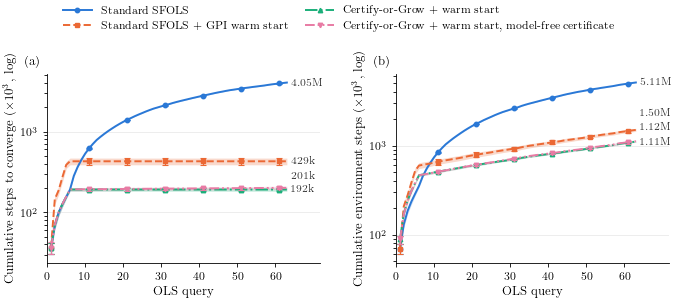

saved ../notes/figures/office_q_ccs_cost.pdf  (TeX rendering: True)

mean +- std over 10 seeds, whole epsilon-CCS:
  Standard SFOLS                     to converge    4050.0k +-   32.0k
  Standard SFOLS                     env steps      5108.5k +-   27.5k
  Standard SFOLS + GPI warm start    to converge     428.5k +-   40.9k
  Standard SFOLS + GPI warm start    env steps      1499.8k +-   56.4k
  Certify-or-Grow + warm start       to converge     191.5k +-    9.1k
  Certify-or-Grow + warm start       env steps      1107.4k +-   13.8k
  Certify-or-Grow + warm start, model-free certificate to converge     201.1k +-    9.1k
  Certify-or-Grow + warm start, model-free certificate env steps      1120.3k +-   33.2k


In [14]:
import shutil

os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"   # MacTeX, if the kernel's PATH lacks it
USE_TEX = shutil.which("latex") is not None

PUB_RC = {
    "text.usetex": USE_TEX,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
}
ARM_STYLE = {
    "standard":      dict(color="#2a78d6", ls="-",  marker="o"),
    "standard-warm": dict(color="#eb6834", ls="--", marker="s"),
    "certify-pool":  dict(color="#1baf7a", ls="-.", marker="^"),
    "certify-mf":    dict(color="#e87ba4", ls=(0, (5, 1.5, 1, 1.5, 1, 1.5)), marker="v"),
}
ARM_LABEL = {"standard": "Standard SFOLS", "standard-warm": "Standard SFOLS + GPI warm start",
             "certify-pool": "Certify-or-Grow + warm start",
             "certify-mf": "Certify-or-Grow + warm start, model-free certificate"}


def cumulative_runs(rs, key):
    curves = [np.concatenate([[0], np.cumsum(per_query(r, key))]) for r in rs]
    n = max(map(len, curves))
    return np.stack([np.pad(c, (0, n - len(c)), mode="edge") for c in curves])


def label_ends(ax, ends, min_gap):
    placed = []
    for arm, (x, y) in sorted(ends.items(), key=lambda kv: kv[1][1]):
        y_txt = max(y, placed[-1] * 1.45) if placed else y      # log axis: multiplicative gap
        placed.append(y_txt)
        ax.annotate(f"{y:.0f}k" if y < 1000 else f"{y / 1000:.2f}M", xy=(x, y),
                    xytext=(x + 1.2, y_txt), va="center", ha="left", fontsize=7.5, color="#333333")


panels = [("log", r"Cumulative steps to converge ($\times 10^3$, log)"),
          ("log_total", r"Cumulative environment steps ($\times 10^3$, log)")]

with plt.rc_context(PUB_RC):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
    for ax, (key, ylabel), tag in zip(axes, panels, "ab"):
        ends, x_max = {}, 0
        for arm in Q_ARMS:
            Y = cumulative_runs(q_runs[arm], key)[:, 1:] / 1000      # from query 1 (log scale)
            mean, std = Y.mean(axis=0), Y.std(axis=0)
            x = np.arange(1, len(mean) + 1)
            st = ARM_STYLE[arm]
            ax.fill_between(x, mean - std, mean + std, color=st["color"], alpha=0.25, lw=0)
            ax.plot(x, mean, color=st["color"], ls=st["ls"], lw=1.8 if st["ls"] == ":" else 1.4,
                    marker=st["marker"], ms=3.2, markevery=10, label=ARM_LABEL[arm])
            ax.errorbar(x[::10], mean[::10], yerr=std[::10], fmt="none", ecolor=st["color"],
                        elinewidth=0.8, capsize=2, capthick=0.8)
            ends[arm] = (x[-1], mean[-1])
            x_max = max(x_max, x[-1])
        label_ends(ax, ends, min_gap=0.0)
        ax.set_yscale("log")
        ax.set_xlim(0, x_max * 1.14)
        ax.set_xticks(np.arange(0, x_max + 1, 10))
        ax.set_xlabel("OLS query")
        ax.set_ylabel(ylabel)
        ax.text(-0.02, 1.03, rf"({tag})", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(axis="y", color="#e6e6e6", lw=0.5)
        ax.set_axisbelow(True)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,
               frameon=False, handlelength=2.6, columnspacing=1.6)
    fig.tight_layout(w_pad=2.0)
    out = os.path.join("..", "notes", "figures", "office_q_ccs_cost.pdf")
    fig.savefig(out)
    plt.show()

print(f"saved {out}  (TeX rendering: {USE_TEX})")
print(f"\nmean +- std over {len(Q_SEEDS)} seeds, whole epsilon-CCS:")
for arm in Q_ARMS:
    for key, name in (("log", "to converge"), ("log_total", "env steps")):
        t = np.array([per_query(r, key).sum() for r in q_runs[arm]]) / 1000
        print(f"  {ARM_LABEL[arm]:34s} {name:12s} {t.mean():8.1f}k +- {t.std():6.1f}k")

# raw per-seed cumulative curves, read by plot_ccs_cost_combined.py (DST + Office figure)
data_dir = os.path.join("..", "notes", "figures", "data")
os.makedirs(data_dir, exist_ok=True)
np.savez(os.path.join(data_dir, "office_q_ccs_cost.npz"),
         **{f"{arm}__{key}": cumulative_runs(q_runs[arm], key) for arm in Q_ARMS for key, _ in panels})


## 5. One-shot transfer with the learned SFs

The same 300 test weights, now building a policy from each arm's learned CCS (seed 0) without any
further learning, and measuring its exact regret averaged over the start states. With an
$\varepsilon$-CCS the guarantee is regret at most $\varepsilon$, not zero.

In [15]:
def gpi_actions_learned(policies, w):
    Q = np.einsum("nsad,d->nsa", np.stack([p.psi_sa for p in policies]), w)
    return np.nan_to_num(Q, nan=-np.inf).max(axis=0).argmax(axis=1)


def election_actions(policies, w):
    j = np.argmax(np.stack([p.psi_s @ w for p in policies]), axis=0)
    return np.stack([p.actions for p in policies])[j, np.arange(S)]


transfer = {}
for arm, label in Q_ARMS.items():
    c = q_runs[arm][0]["ccs"]
    transfer[f"{label} + GPI"] = lambda w, c=c: gpi_actions_learned(c, w)
    transfer[f"{label} + election"] = lambda w, c=c: election_actions(c, w)
transfer["basis only (6 corners) + GPI"] = lambda w, c=q_runs["certify-pool"][0]["basis"]: gpi_actions_learned(c, w)

print(f"{len(test_weights)} unseen weights; regret = V*_w - V^pi_w averaged over the 7 start states\n")
print(f"{'':42s} {'weights w/ regret':>18s} {'max regret':>11s} {'mean regret':>12s}")
for k, f in transfer.items():
    reg = np.array([(V - value(f(w), w))[INIT].mean() for w, V in zip(test_weights, V_star_test)])
    print(f"{k:42s} {int((reg > 1e-6).sum()):>18d} {reg.max():>11.5f} {reg.mean():>12.6f}")

300 unseen weights; regret = V*_w - V^pi_w averaged over the 7 start states

                                            weights w/ regret  max regret  mean regret


standard SFOLS + GPI                                        0     0.00000     0.000000


standard SFOLS + election                                   0     0.00000     0.000000


standard + GPI warm start + GPI                             0     0.00000     0.000000


standard + GPI warm start + election                        0     0.00000     0.000000


CoG + warm start + GPI                                      0     0.00000     0.000000


CoG + warm start + election                                 0     0.00000     0.000000


CoG + warm start, model-free + GPI                          0     0.00000     0.000000


CoG + warm start, model-free + election                     0     0.00000     0.000000
basis only (6 corners) + GPI                                0     0.00000     0.000000


## 6. Reading the result

*(Figures from the executed run; Q-learning numbers are over 10 seeds.)*

**Same $\varepsilon$-CCS, every method, every seed.** With $\varepsilon = 0.05$ OLS makes 63
queries and every one adds a CCS point. Exact standard SFOLS, exact Certify-or-Grow and all four
learned arms (on all 10 seeds) return the same 63 points; every learned SF table is exact. Over 300
random weights the best CCS point is within 0.0053 of the true optimum (bound: 0.05).

**Exact solves.** Certify-or-Grow needs 6 exact solves instead of 63 and 3.35x fewer linear solves;
all 63 queries certify, 0 fallbacks. Wall-clock time is the same (~10 s), because ~97% of it is
OLS's own bookkeeping (the corner LPs), identical for both.

**Learned SFs.**

| arm | env steps | steps to converge |
|---|---|---|
| standard SFOLS | $5.11 \pm 0.03$M | $4.05 \pm 0.03$M |
| standard + GPI warm start | $1.50 \pm 0.06$M | $0.43 \pm 0.04$M |
| Certify-or-Grow | $1.11 \pm 0.01$M | $0.19 \pm 0.01$M |
| Certify-or-Grow + pool | identical to Certify-or-Grow | |

Certify-or-Grow is **4.6x** cheaper than standard SFOLS in env steps (**21x** in steps to converge)
and **1.4x** cheaper than the warm-started baseline (2.2x in steps to converge).

**Why the picture differs from DST.**
- After the 6 basis corners, *every* query costs Certify-or-Grow **0 steps to converge**: the GPI
  start over the 6 corners is already the exact metapolicy at each queried weight. Consistently,
  GPI over the 6 corners alone has zero regret on all 300 test weights - on Office the canonical
  corners already solve every weight (as in `notes/adaptive_basis.tex`'s Office results for $k=6$).
  Its steps to converge are the corners' cost, nothing more.
- So the pool arm has nothing left to speed up: it is identical to plain Certify-or-Grow (the two
  curves coincide).
- The remaining cost is *confirmation*: each restricted learn still revisits every allowed
  $(s,a)$ once (~16k env steps per query). That is cheaper than the warm-started baseline's
  confirmation over all 4 actions, which is where the 1.4x comes from.
- The warm-started baseline pays more than standard SFOLS for queries 2-6 (the corners): learning
  a corner from a non-optimistic GPI start is slower than from an optimistic one. After that it
  also converges in 0 steps at almost every query.
- Standard SFOLS never benefits: each of its 63 queries relearns a full table from an optimistic
  start (~50-80k steps each).

**Without a model (fifth arm).** Reading the certificate off a learned table keeps the same
$\varepsilon$-CCS, exact tables and certifications, and costs **28% more environment steps** than
the model-based check ($1.42 \pm 0.02$M vs $1.11 \pm 0.01$M; steps to converge unchanged, since
nothing new has to be learned). It remains **3.6x** cheaper than standard SFOLS but only **1.07x**
cheaper than the warm-started baseline. Smaller overhead than on DST (3.9x there), because Office's
basis has 6 policies, so $B(s)$ already covers more of the 4 actions and fewer entries lie outside it.

**Caveats.**
- This is an $\varepsilon$-CCS: the exact CCS over 7 start states is too large for OLS to finish.
- Same hybrid as DST: learned SFs, model-based certificate.
- Exploring starts here also randomize the first action (Part 4); notebook 13 randomizes only the
  start state, so its absolute step counts are not directly comparable to these.
- Wall-clock times of the learned runs are not reported: 40 runs shared 8 CPUs.